In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report

In [43]:
train = pd.read_csv("cifar-10.csv")
# print(train.head)
print(train.shape)

(50000, 3073)


In [44]:
x=train.drop("label",axis=1).values
y=train["label"].values
print(x.shape)
print(y.shape)
print(np.unique(y))

(50000, 3072)
(50000,)
[0 1 2 3 4 5 6 7 8 9]


In [45]:
x = x.reshape(-1,3,32,32).transpose(0,2,3,1)
x=x.astype("float32")/255.0
print("image shape:",x.shape)

image shape: (50000, 32, 32, 3)


In [46]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y)
print(x_train.shape)
print(x_test.shape)

(40000, 32, 32, 3)
(10000, 32, 32, 3)


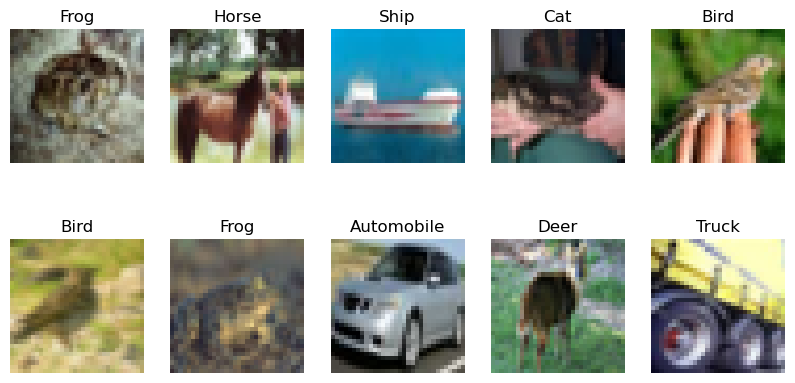

In [47]:
class_names=[
    "Airplane","Automobile","Bird","Cat","Deer",
    "Dog","Frog","Horse","Ship","Truck"
]

plt.figure(figsize=(10,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.show()

In [48]:
model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation="relu",input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),    
    layers.Dense(10,activation="softmax")
])

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [50]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 7200)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │          72,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 72,906 (284.79 KB)

 Trainable params: 72,906 (284.79 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=64,
    validation_data=(x_test,y_test)
)

Epoch 1/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.4372 - loss: 1.6051 - val_accuracy: 0.5073 - val_loss: 1.4133
Epoch 2/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.5553 - loss: 1.2799 - val_accuracy: 0.5725 - val_loss: 1.2435
Epoch 3/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.5965 - loss: 1.1587 - val_accuracy: 0.5906 - val_loss: 1.1901
Epoch 4/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.6247 - loss: 1.0877 - val_accuracy: 0.5748 - val_loss: 1.1935
Epoch 5/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6413 - loss: 1.0355 - val_accuracy: 0.6100 - val_loss: 1.1190
Epoch 6/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.6573 - loss: 0.9951 - val_accuracy: 0.6223 - val_loss: 1.0858
Epoch 7/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6675 - loss: 0.9670 - val_accuracy: 0.6290 - val_loss: 1.0795
Epoch 8/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.6806 - loss: 0.9302 - 

In [52]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("loss:",test_loss)
print("accuracy:",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6449 - loss: 1.0540
loss: 1.0539820194244385
accuracy: 0.6449000239372253


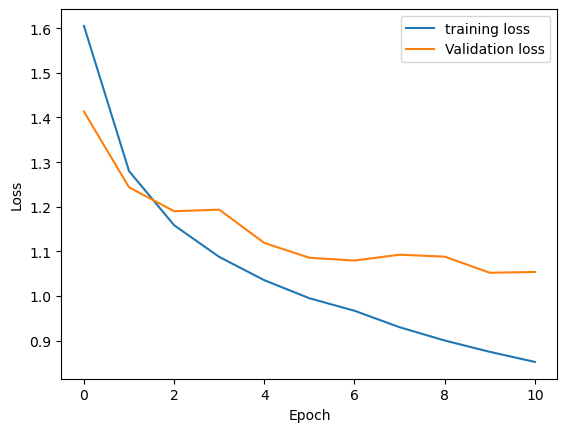

In [53]:
plt.plot(history.history["loss"],label="training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

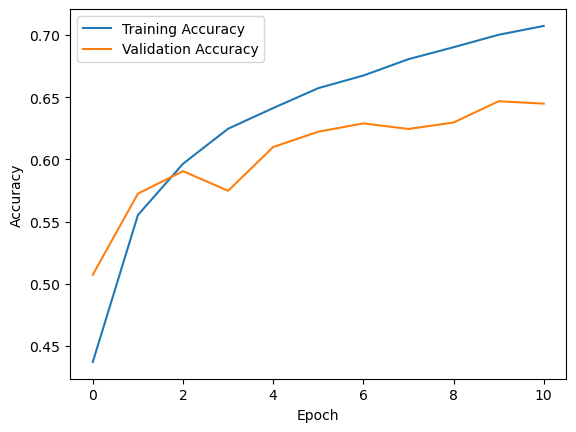

In [57]:
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

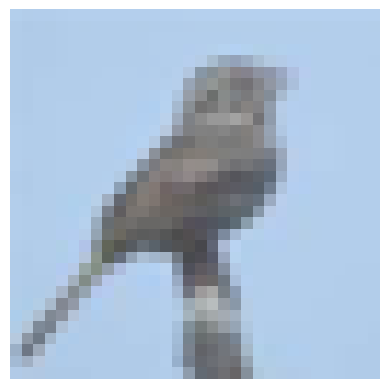

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
Actual: Bird
Predicted: Bird


In [61]:
index=0
plt.imshow(x_test[index])
plt.axis("off")
plt.show()

prediction = model.predict(x_test[index].reshape(1,32,32,3))
print("Actual:",class_names[y_test[index]])
print("Predicted:",class_names[np.argmax(prediction)])

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report

train = pd.read_csv("cifar-10.csv")
# print(train.head)
print(train.shape)

x=train.drop("label",axis=1).values
y=train["label"].values
print(x.shape)
print(y.shape)
print(np.unique(y))

x = x.reshape(-1,3,32,32).transpose(0,2,3,1)
x=x.astype("float32")/255.0
print("image shape:",x.shape)

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y)
print(x_train.shape)
print(x_test.shape)

class_names=[
    "Airplane","Automobile","Bird","Cat","Deer",
    "Dog","Frog","Horse","Ship","Truck"
]

plt.figure(figsize=(10,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.show()

model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation="relu",input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),    
    layers.Dense(10,activation="softmax")
])

model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=64,
    validation_data=(x_test,y_test)
)

test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("loss:",test_loss)
print("accuracy:",test_accuracy)

plt.plot(history.history["loss"],label="training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

index=0
plt.imshow(x_test[index])
plt.axis("off")
plt.show()

prediction = model.predict(x_test[index].reshape(1,32,32,3))
print("Actual:",class_names[y_test[index]])
print("Predicted:",class_names[np.argmax(prediction)])